# Human vs AI vs Fusion text classification (UCU AI 2026, NLP homework)

Pipeline: **0 Setup → 1 EDA → 2 Fixed split → 3 TF-IDF baseline → 4 Transformer encoder (+ long-text handling) → 5 Further experiments (long-text strategy, perplexity + stylometry features, ensemble) → 6 xAI → 7 Final submission**.

Rules reminder: train on `train.csv` only, open-weight models only, fit every vectorizer/scaler on the train split only. All comparisons use macro-F1 on the **same fixed validation split**. Every model is trained on the train split and evaluated on the validation split; no hyperparameters are tuned on validation, and validation is used only to compare the final candidates.

Run on Colab/Kaggle with a GPU. Section 3 and EDA run on CPU. Set paths in the config cell.

In [1]:
!pip -q install transformers accelerate lightgbm shap scikit-learn pandas matplotlib seaborn 2>&1 | tail -n 1

In [2]:
import os, re, gc, json, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

# ---------------- CONFIG ----------------
import glob
_hits = glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True)
assert _hits, "train.csv not found: add the competition via 'Add Input' in the Kaggle sidebar (or upload the files)"
DATA_DIR   = os.path.dirname(_hits[0]); print("DATA_DIR =", DATA_DIR, os.listdir(DATA_DIR))
OUT_DIR    = "./outputs"; os.makedirs(OUT_DIR, exist_ok=True)
SEED       = 42
N_SUB      = 40_000      # fixed subsample of train used for ALL models (stay within 20-50k)
VAL_FRAC   = 0.2       # validation: used only to evaluate/compare finished models trained on the train split (no hyperparameter tuning on it)
BACKBONE   = "xlm-roberta-base"      # alternatives: "microsoft/mdeberta-v3-base", "xlm-roberta-large"
MAX_LEN    = 512
EPOCHS     = 2
BATCH      = 8
LR         = 2e-5
LM_NAME    = "Qwen/Qwen2.5-0.5B"     # open-weight LM for perplexity features
PPL_TRAIN_N = 8_000                  # number of TRAIN rows used to fit the perplexity/stylometry model (5b)
# ----------------------------------------

LABELS = ["human", "ai", "fusion"]; L2I = {l:i for i,l in enumerate(LABELS)}
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except Exception: pass
seed_all()
def mf1(y, p): return f1_score(y, p, average="macro")

DATA_DIR = /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026 ['sample_submission.csv', 'train.csv', 'test.csv']


## 1. EDA

In [3]:
train = pd.read_csv(f"{DATA_DIR}/train.csv"); test = pd.read_csv(f"{DATA_DIR}/test.csv")
sub_tmpl = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")
for d in (train, test): d["text"] = d["text"].fillna("").astype(str)
print("empty texts: train", (train.text.str.strip()=="").sum(), "| test", (test.text.str.strip()=="").sum())
print(train.shape, test.shape)
train["n_words"] = train.text.str.split().str.len(); test["n_words"] = test.text.str.split().str.len()
print(train.label.value_counts(normalize=True).round(3).to_dict())
display(pd.crosstab(train.lang, train.label, normalize="index").round(3))
display(pd.crosstab(train.domain, train.label, normalize="index").round(3))
display(pd.crosstab([train.lang, train.domain], train.label))
print("test lang/domain share:"); display(test.groupby(["lang","domain"]).size().div(len(test)).round(3).to_frame("share"))

empty texts: train 0 | test 0
(272352, 5) (25000, 4)
{'ai': 0.448, 'fusion': 0.307, 'human': 0.245}


label,ai,fusion,human
lang,,,
de-DE,0.385,0.340,0.275
en-EN,0.463,0.299,0.238


label,ai,fusion,human
domain,,,
arxiv_papers,0.843,0.128,0.028
blog_authorship_corpus,0.387,0.306,0.307
bundestag,0.382,0.342,0.277
cnn_news,0.440,0.257,0.302
euro_court_cases,0.404,0.368,0.228
gutenberg,0.915,0.051,0.034
house_of_commons,0.480,0.302,0.218
student_essays,0.399,0.370,0.231


label                            ai  fusion  human
lang  domain                                      
de-DE bundestag               19977   17887  14479
      gutenberg                 360      37     31
en-EN arxiv_papers            12050    1833    407
      blog_authorship_corpus  15684   12397  12466
      cnn_news                19488   11402  13395
      euro_court_cases        11141   10160   6277
      gutenberg                6359     341    216
      house_of_commons        15298    9608   6953
      student_essays          21583   20017  12506

test lang/domain share:


share
lang  domain                       
de-DE bundestag               0.143
      gutenberg               0.004
en-EN arxiv_papers            0.067
      blog_authorship_corpus  0.178
      cnn_news                0.197
      euro_court_cases        0.064
      gutenberg               0.070
      house_of_commons        0.118
      student_essays          0.159

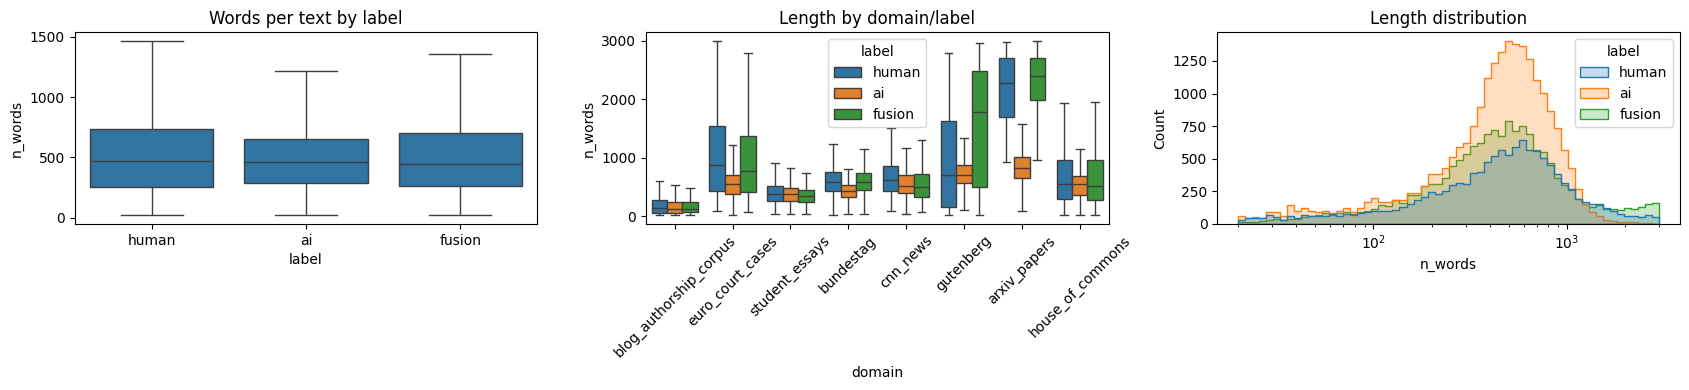

share of texts > ~380 words (likely > 512 tokens): 0.617


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17,4))
sns.boxplot(data=train.sample(50000, random_state=0), x="label", y="n_words", order=LABELS, ax=ax[0], showfliers=False); ax[0].set_title("Words per text by label")
sns.boxplot(data=train.sample(50000, random_state=0), x="domain", y="n_words", hue="label", hue_order=LABELS, ax=ax[1], showfliers=False)
ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Length by domain/label")
sns.histplot(data=train.sample(50000, random_state=0), x="n_words", hue="label", hue_order=LABELS, bins=60, log_scale=True, element="step", ax=ax[2]); ax[2].set_title("Length distribution")
plt.tight_layout(); plt.show()
print("share of texts > ~380 words (likely > 512 tokens):", (train.n_words > 380).mean().round(3))

In [5]:
# Simple style statistics per class: what makes fusion different?
def quick_stats(t):
    w = t.split(); sents = re.split(r"(?<=[.!?])\s+", t)
    if not w: return pd.Series({k: np.nan for k in ["avg_word_len","avg_sent_len","ttr","punct_ratio","newline_ratio","digit_ratio"]})   # empty-text guard
    return pd.Series({"avg_word_len": np.mean([len(x) for x in w]), "avg_sent_len": len(w)/max(len(sents),1),
                      "ttr": len(set(x.lower() for x in w))/len(w), "punct_ratio": sum(c in ",;:()-\"'" for c in t)/len(t),
                      "newline_ratio": t.count("\n")/len(t), "digit_ratio": sum(c.isdigit() for c in t)/len(t)})
s = train.sample(6000, random_state=1)
st = s.text.apply(quick_stats); st["label"] = s.label.values
display(st.groupby("label").mean().loc[LABELS].round(4))
for lab in LABELS:
    cand = train[(train.label==lab)&(train.lang=="en-EN")&(train.n_words<150)&(train.n_words>=20)]
    if len(cand) == 0: print(f"\n=== {lab}: no short English example ==="); continue
    r = cand.sample(1, random_state=3).iloc[0]
    print(f"\n=== {lab} | {r.domain} ===\n{r.text[:700]}")

,avg_word_len,avg_sent_len,ttr,punct_ratio,newline_ratio,digit_ratio
label,,,,,,
human,4.9668,18.8589,0.5498,0.0142,0.0,0.0082
ai,5.5478,18.5201,0.6042,0.0146,0.0,0.0022
fusion,5.1480,17.7624,0.5690,0.0136,0.0,0.0076



=== human | blog_authorship_corpus ===
New on the bookshelf: urlLink Invisible Frontier: Exploring the Tunnels, Ruins, and Rooftops of Hidden New York by L.B. Deyo & David 'Lefty' Leibowitz. A fun read, though you expect that 'urban adventuring' would be a bit more wild and fun. Still worth a rainy afternoon.

=== ai | blog_authorship_corpus ===
Power's out. Again. Stupidest thing ever. Can't even watch TV 🙄 Stuck in the dark, bored outta my mind. AIM is still up tho so that's cool I guess... but like, nobody's on. Oreos calling 😩 Feeling kinda restless. Like, need to do something, anything. But there's nothing to do.

=== fusion | blog_authorship_corpus ===
...and it's fascinating how these moments reflect his unique perspective on life. I heard the last part of this quote elsewhere. This text comes from urlLink this blog post . Don't know where Bush said it, if at all, but sounds in line with other weird things he is known to have said.


**EDA notes (fill in after running):** class balance per language/domain, length differences between classes, and whether fusion sits between human and ai in style statistics. Because a human text and its AI/fusion versions are always on the same side of the split, our random validation split can contain siblings (same source text) in both train and val, which makes validation optimistic. Section 2 measures this with a quick near-duplicate check.

## 2. Fixed subsample and train / validation split (used by every model)

In [6]:
sub = train.sample(N_SUB, random_state=SEED).reset_index(drop=True)
strat = sub.label + "_" + sub.lang
tr, va = train_test_split(sub, test_size=VAL_FRAC, random_state=SEED, stratify=strat)
tr, va = tr.reset_index(drop=True), va.reset_index(drop=True)
ytr, yva = tr.label.map(L2I).values, va.label.map(L2I).values
print(len(tr), len(va), va.label.value_counts(normalize=True).round(3).to_dict())

# Sibling-leak check: share of val texts whose first 60 characters-of-words appear in train (cheap proxy)
key = lambda s: " ".join(s.split()[:12]).lower()
trk = set(tr.text.map(key)); print("val rows sharing first-12-words with a train row:", np.mean([key(t) in trk for t in va.text]).round(3), "(cannot detect paraphrased siblings)")

32000 8000 {'ai': 0.449, 'fusion': 0.307, 'human': 0.244}
val rows sharing first-12-words with a train row: 0.137 (cannot detect paraphrased siblings)


## 3. Baseline: TF-IDF + classical models
Vectorizers are fit on the **train split only**. A small parameter search (C for LinearSVC and LogReg) is run inside the train split with an internal holdout; the chosen models are refit on the full train split and evaluated on val.

vectorized (32000, 633030) 250s
LinearSVC 0.1 0.8302 16s
LinearSVC 0.3 0.8395 22s
LinearSVC 1.0 0.838 42s
LogReg 3 0.8559 149s
LogReg 10 0.8544 130s
LogReg 30 0.8538 104s


,model,C,internal_holdout_macroF1
3,LogReg,3.0,0.855867
4,LogReg,10.0,0.854371
5,LogReg,30.0,0.853759
1,LinearSVC,0.3,0.839523
2,LinearSVC,1.0,0.838021
0,LinearSVC,0.1,0.830205


LinearSVC (C=0.3) -> val macro-F1: 0.8440
LogReg (C=3.0) -> val macro-F1: 0.8644
reference baseline: LogReg
              precision    recall  f1-score   support

       human      0.752     0.856     0.801      1954
          ai      0.985     0.987     0.986      3592
      fusion      0.858     0.761     0.806      2454

    accuracy                          0.886      8000
   macro avg      0.865     0.868     0.864      8000
weighted avg      0.889     0.886     0.886      8000



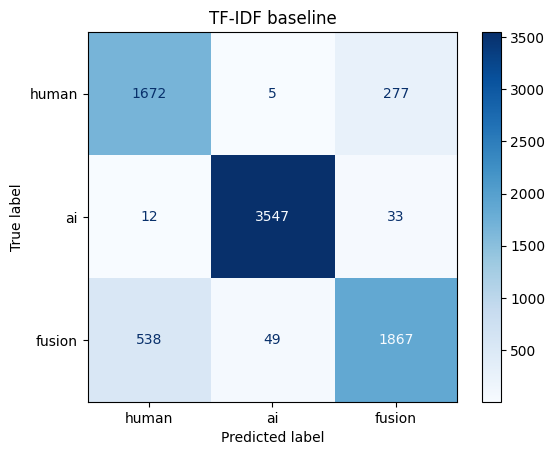

BASELINE macro-F1: 0.8644
macro-F1 by language: {'de-DE': 0.877, 'en-EN': 0.861}


,macroF1
domain,
arxiv_papers,0.838
blog_authorship_corpus,0.755
bundestag,0.879
cnn_news,0.864
euro_court_cases,0.908
gutenberg,0.758
house_of_commons,0.867
student_essays,0.895


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from scipy.sparse import hstack
import time

t0 = time.time()
def make_vecs():
    return (TfidfVectorizer(ngram_range=(1,2), min_df=3, max_features=300_000, sublinear_tf=True),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(2,5), min_df=5, max_features=400_000, sublinear_tf=True, lowercase=False))
vw, vc = make_vecs()   # final vectorizers: fitted on ALL train rows
Xtr = hstack([vw.fit_transform(tr.text), vc.fit_transform(tr.text)]).tocsr()
Xva = hstack([vw.transform(va.text),  vc.transform(va.text)]).tocsr()
print("vectorized", Xtr.shape, f"{time.time()-t0:.0f}s")

# Small parameter search INSIDE the train split (80/20 internal holdout, with vectorizers refit on the internal-train rows only); val is not used for any choice
idx_in, idx_ho = train_test_split(np.arange(len(tr)), test_size=0.2, random_state=SEED, stratify=ytr)
# temporary vectorizers fitted ONLY on the internal-train rows, so the holdout influences neither vocabulary nor IDF
vw_i, vc_i = make_vecs(); t_in, t_ho = tr.text.iloc[idx_in], tr.text.iloc[idx_ho]
X_in = hstack([vw_i.fit_transform(t_in), vc_i.fit_transform(t_in)]).tocsr(); X_ho = hstack([vw_i.transform(t_ho), vc_i.transform(t_ho)]).tocsr()
make = lambda name, C: (LinearSVC(C=C, class_weight="balanced") if name=="LinearSVC"
                        else LogisticRegression(C=C, max_iter=300, class_weight="balanced"))
grid = [("LinearSVC", C) for C in [0.1, 0.3, 1.0]] + [("LogReg", C) for C in [3, 10, 30]]
rows = []
for name, C in grid:
    t1 = time.time(); m = make(name, C).fit(X_in, ytr[idx_in])
    rows.append((name, C, mf1(ytr[idx_ho], m.predict(X_ho)))); print(name, C, round(rows[-1][2],4), f"{time.time()-t1:.0f}s")
res_df = pd.DataFrame(rows, columns=["model","C","internal_holdout_macroF1"]).sort_values("internal_holdout_macroF1", ascending=False); display(res_df)

# Refit the best configuration of each family on the full train split, then evaluate on val
fam_models = {}
for name in ["LinearSVC", "LogReg"]:
    C = res_df[res_df.model==name].iloc[0].C; fam_models[name] = make(name, C).fit(Xtr, ytr)
    print(f"{name} (C={C}) -> val macro-F1: {mf1(yva, fam_models[name].predict(Xva)):.4f}")
best_name = res_df.iloc[0].model
base = fam_models[best_name]       # reference baseline = best family by internal holdout (not by val)
lr_b = fam_models["LogReg"]        # best-C LogReg, gives probabilities for the ensemble
print("reference baseline:", best_name)
pva_base = base.predict(Xva)
print(classification_report(yva, pva_base, target_names=LABELS, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yva, pva_base), display_labels=LABELS).plot(cmap="Blues"); plt.title("TF-IDF baseline"); plt.show()
BASE_F1 = mf1(yva, pva_base); print("BASELINE macro-F1:", round(BASE_F1,4))
# per-language / per-domain breakdown
def mf1_by(pred, col):
    d = va.assign(y=yva, p=pred); return d.groupby(col)[["y","p"]].apply(lambda g: mf1(g.y, g.p)).round(3)
print("macro-F1 by language:", mf1_by(pva_base, "lang").to_dict()); display(mf1_by(pva_base, "domain").to_frame("macroF1"))


# Valid first submission right away (baseline)
Xte = hstack([vw.transform(test.text), vc.transform(test.text)]).tocsr()
pd.DataFrame({"id": test.id, "label": [LABELS[i] for i in base.predict(Xte)]}).set_index("id").loc[sub_tmpl.id].reset_index().to_csv(f"{OUT_DIR}/sub_baseline.csv", index=False)

In [8]:
# Calibrated-ish scores of the baseline for later ensembling (LogReg on same features)
P_base_va, P_base_te = lr_b.predict_proba(Xva), lr_b.predict_proba(Xte)   
best_lr_C = res_df[res_df.model == "LogReg"].iloc[0]["C"]
print(f"LogReg C={best_lr_C:g} val macro-F1:", round(mf1(yva, P_base_va.argmax(1)), 4))

# Leakage diagnostic (evaluation only): nearest-neighbour cosine similarity of every val text to the train texts (word TF-IDF, rows are L2-normalised)
n_w = len(vw.vocabulary_); Xtr_w, Xva_w = Xtr[:, :n_w].tocsr(), Xva[:, :n_w].tocsr()
sims, nbr = [], []
for i in range(0, Xva_w.shape[0], 250):
    S = Xva_w[i:i+250] @ Xtr_w.T
    sims.append(S.max(axis=1).toarray().ravel()); nbr.append(np.asarray(S.argmax(axis=1)).ravel())
nn_sim, nn_idx = np.concatenate(sims), np.concatenate(nbr)
va["nn_sim"] = nn_sim; LOW = nn_sim <= np.median(nn_sim)      # LOW = half of val least similar to any train text
display(va.groupby("label").nn_sim.describe().round(3).loc[LABELS])
print("val rows with nn cosine > 0.5:", (nn_sim > 0.5).mean().round(3), "| > 0.8:", (nn_sim > 0.8).mean().round(3))
# does the id encode the source text? compare ids of near-duplicate pairs (a share far above chance would allow a grouped split)
hi = np.where(nn_sim > 0.8)[0]; print("id examples:", va.id.head(3).tolist(), "| id lengths:", sorted(train.id.str.len().unique())[:5])
if len(hi): print(f"near-duplicate pairs: {len(hi)} | share with the same 2-char id prefix: {np.mean([va.id.iloc[i][:2]==tr.id.iloc[nn_idx[i]][:2] for i in hi]):.3f} (chance is ~0.004 if ids are random hex)")

LogReg C=3 val macro-F1: 0.8644


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
human,1954.0,0.273,0.217,0.063,0.145,0.196,0.273,0.996
ai,3592.0,0.210,0.078,0.065,0.156,0.202,0.249,0.837
fusion,2454.0,0.304,0.239,0.064,0.160,0.206,0.307,1.000


val rows with nn cosine > 0.5: 0.094 | > 0.8: 0.04
id examples: ['bf5f69', '65c364', 'c1101a'] | id lengths: [np.int64(6)]
near-duplicate pairs: 323 | share with the same 2-char id prefix: 0.000 (chance is ~0.004 if ids are random hex)


## 4. Fine-tuned multilingual encoder
Long texts (median 463 words, up to 3000) exceed 512 tokens. Default strategy: **head + tail truncation** (first 320 + last 190 tokens). Section 5a compares this with sliding-window chunking at inference.

In [9]:
import torch, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
dev = "cuda" if torch.cuda.is_available() else "cpu"; print(dev)
tok = AutoTokenizer.from_pretrained(BACKBONE)
HEAD, TAIL = 320, MAX_LEN - 2 - 320

def ids_head_tail(text):
    ids = tok(
        text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    if len(ids) > MAX_LEN - 2:
        ids = ids[:HEAD] + ids[-TAIL:]

    return [tok.cls_token_id] + ids + [tok.sep_token_id]

class DS(Dataset):
    def __init__(s, texts, y=None): s.ids = [ids_head_tail(t) for t in texts]; s.y = y
    def __len__(s): return len(s.ids)
    def __getitem__(s, i): return s.ids[i], (-1 if s.y is None else int(s.y[i]))
def collate(b):
    L = max(len(x[0]) for x in b); pad = tok.pad_token_id
    ids = torch.tensor([x[0]+[pad]*(L-len(x[0])) for x in b]); att = (ids!=pad).long()
    return ids, att, torch.tensor([x[1] for x in b])

@torch.no_grad()
def predict_proba_ids(model, id_lists, bs=16):
    model.eval(); order = np.argsort([len(x) for x in id_lists]); out = np.zeros((len(id_lists),3), dtype=np.float32)
    for i in range(0, len(order), bs):
        idx = order[i:i+bs]; b = [(id_lists[j], 0) for j in idx]; ids, att, _ = collate(b)
        with torch.autocast("cuda", dtype=torch.float16, enabled=dev=="cuda"):
            lg = model(input_ids=ids.to(dev), attention_mask=att.to(dev)).logits
        out[idx] = F.softmax(lg.float(), -1).cpu().numpy()
    return out

cuda


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (652 > 512). Running this sequence through the model will result in indexing errors


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ep0 step0/4000 loss 1.0966
ep0 step500/4000 loss 0.8025
ep0 step1000/4000 loss 0.6682
ep0 step1500/4000 loss 0.5806
ep0 step2000/4000 loss 0.5349
ep0 step2500/4000 loss 0.5007
ep0 step3000/4000 loss 0.4706
ep0 step3500/4000 loss 0.4499
ep1 step0/4000 loss 0.3231
ep1 step500/4000 loss 0.2612
ep1 step1000/4000 loss 0.2568
ep1 step1500/4000 loss 0.2537
ep1 step2000/4000 loss 0.2555
ep1 step2500/4000 loss 0.2572
ep1 step3000/4000 loss 0.2556
ep1 step3500/4000 loss 0.2552


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

ENCODER (head+tail) macro-F1: 0.8907 | baseline: 0.8644
              precision    recall  f1-score   support

       human      0.861     0.788     0.823      1954
          ai      0.981     0.998     0.990      3592
      fusion      0.842     0.877     0.859      2454

    accuracy                          0.910      8000
   macro avg      0.895     0.888     0.891      8000
weighted avg      0.909     0.910     0.909      8000



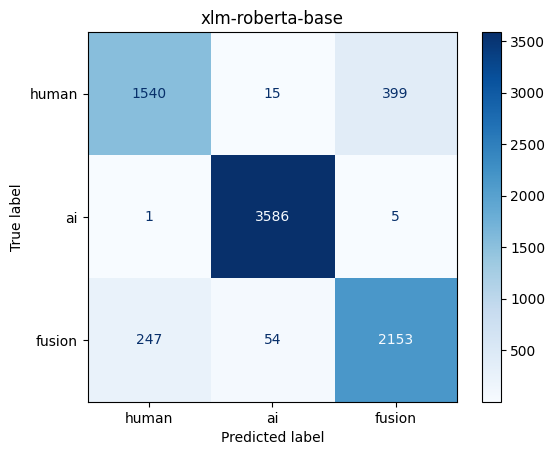

encoder macro-F1 by language: {'de-DE': 0.899, 'en-EN': 0.888}


,macroF1
domain,
arxiv_papers,0.609
blog_authorship_corpus,0.827
bundestag,0.901
cnn_news,0.941
euro_court_cases,0.834
gutenberg,0.639
house_of_commons,0.906
student_essays,0.915


In [10]:
def finetune(tr_texts, ytr_, name):   # fixed number of epochs, the final weights are kept
    seed_all(); ds_tr = DS(tr_texts, ytr_)
    model = AutoModelForSequenceClassification.from_pretrained(BACKBONE, num_labels=3).to(dev)
    dl = DataLoader(ds_tr, batch_size=BATCH, shuffle=True, collate_fn=collate)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    steps = EPOCHS*len(dl); sch = get_linear_schedule_with_warmup(opt, int(0.06*steps), steps)
    scaler = torch.cuda.amp.GradScaler(enabled=dev=="cuda")
    for ep in range(EPOCHS):
        model.train(); tot = 0
        for k,(ids,att,y) in enumerate(dl):
            with torch.autocast("cuda", dtype=torch.float16, enabled=dev=="cuda"):
                loss = model(input_ids=ids.to(dev), attention_mask=att.to(dev), labels=y.to(dev)).loss
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()
            if k % 500 == 0: print(f"ep{ep} step{k}/{len(dl)} loss {tot/(k+1):.4f}")
    model.save_pretrained(f"{OUT_DIR}/{name}"); tok.save_pretrained(f"{OUT_DIR}/{name}")
    json.dump(dict(backbone=BACKBONE, max_len=MAX_LEN, head=HEAD, tail=TAIL, epochs=EPOCHS, batch=BATCH, lr=LR, seed=SEED, n_sub=N_SUB, val_frac=VAL_FRAC),
              open(f"{OUT_DIR}/{name}/train_config.json","w"), indent=1)
    return model

model = finetune(tr.text.tolist(), ytr, "encoder_headtail")
P_enc_va = predict_proba_ids(model, DS(va.text.tolist()).ids)
ENC_F1 = mf1(yva, P_enc_va.argmax(1)); print("ENCODER (head+tail) macro-F1:", round(ENC_F1,4), "| baseline:", round(BASE_F1,4))
print(classification_report(yva, P_enc_va.argmax(1), target_names=LABELS, digits=3))
ConfusionMatrixDisplay(confusion_matrix(yva, P_enc_va.argmax(1)), display_labels=LABELS).plot(cmap="Blues"); plt.title(BACKBONE); plt.show()
print("encoder macro-F1 by language:", mf1_by(P_enc_va.argmax(1), "lang").to_dict()); display(mf1_by(P_enc_va.argmax(1), "domain").to_frame("macroF1"))

## 5. Further experiments (each compared with the fixed reference = encoder head+tail, same val split)
- **5a** long-text handling: sliding-window chunk averaging at inference
- **5b** perplexity (open-weight LM) + stylometric features, model fitted on train rows only, then blended with the encoder
- **5c** ensemble of encoder + TF-IDF (fixed equal weights; the TF-IDF LogReg is less confident than the encoder, so the encoder dominates in effect; the printed mean confidences show how much)

In [11]:
def chunk_ids(text, win=MAX_LEN-2, stride=384, max_chunks=6):
    ids = tok(
        text,
        add_special_tokens=False,
        truncation=False
    )["input_ids"]

    def add_special(chunk):
        return [tok.cls_token_id] + chunk + [tok.sep_token_id]

    if len(ids) <= win:
        return [add_special(ids)]

    starts = list(range(0, len(ids)-win, stride))

    if starts[-1] != len(ids)-win:
        starts.append(len(ids)-win)

    if len(starts) > max_chunks:
        starts = starts[:max_chunks-1] + [starts[-1]]

    return [add_special(ids[s:s+win]) for s in starts]
def predict_chunked(model, texts):
    all_ids, owner = [], []
    for i,t in enumerate(texts):
        c = chunk_ids(t); all_ids += c; owner += [i]*len(c)
    P = predict_proba_ids(model, all_ids); owner = np.array(owner)
    return np.stack([P[owner==i].mean(0) for i in range(len(texts))])
P_chunk_va = predict_chunked(model, va.text.tolist())
print("5a chunk-avg macro-F1:", round(mf1(yva, P_chunk_va.argmax(1)),4), "vs head+tail", round(ENC_F1,4))
long_mask = (va.n_words > 380).values
print("on long texts only: chunk", round(mf1(yva[long_mask], P_chunk_va[long_mask].argmax(1)),4), "| head+tail", round(mf1(yva[long_mask], P_enc_va[long_mask].argmax(1)),4))

5a chunk-avg macro-F1: 0.8536 vs head+tail 0.8907
on long texts only: chunk 0.8295 | head+tail 0.8912


In [12]:
# 5b. Perplexity features from an open-weight LM + stylometry. The feature model is fitted on TRAIN rows only and evaluated on val.
from transformers import AutoModelForCausalLM
model.to("cpu"); gc.collect(); torch.cuda.empty_cache()   # free GPU memory for the LM
lm_tok = AutoTokenizer.from_pretrained(LM_NAME); lm = AutoModelForCausalLM.from_pretrained(LM_NAME, torch_dtype=torch.float16 if dev=="cuda" else torch.float32).to(dev).eval()
if lm_tok.pad_token is None: lm_tok.pad_token = lm_tok.eos_token

@torch.no_grad()
def ppl_features(texts, max_tokens=256, bs=4):
    # memory-safe: small batches, full-vocab tensors are built for one text at a time (~0.3 GB) and freed
    texts = [t if t.strip() else "." for t in texts]      # empty-text guard
    feats = []
    for i in range(0, len(texts), bs):
        enc = lm_tok(texts[i:i+bs], return_tensors="pt", truncation=True, max_length=max_tokens, padding=True).to(dev)
        logits = lm(**enc).logits[:, :-1]; tgt = enc.input_ids[:, 1:]; m = enc.attention_mask[:, 1:].bool()
        for j in range(tgt.size(0)):
            lp = F.log_softmax(logits[j][m[j]].float(), -1); t = tgt[j][m[j]]
            a = lp.gather(-1, t[:,None])[:,0]; e = -(lp.exp()*lp).sum(-1); r = (lp > a[:,None]).sum(-1).float()
            feats.append([a.mean().item(), a.std().item(), e.mean().item(), (a+e).mean().item(), (r==0).float().mean().item(),
                          (r<10).float().mean().item(), torch.log1p(r).mean().item()])
            del lp
        del logits, enc
    return np.nan_to_num(np.array(feats))     # std of a 1-token text is NaN
def stylo_one(t):
    w = t.split()
    if not w: return [0.0]*7                                  # empty-text guard
    s_ = re.split(r"(?<=[.!?])\s+", t)
    return [np.mean([len(x) for x in w]), len(w)/max(len(s_),1), len(set(x.lower() for x in w))/len(w),
            sum(c in ",;:()-" for c in t)/len(t), t.count("\n")/len(t), sum(c.isdigit() for c in t)/len(t), np.log(len(w))]
def stylo(texts): return np.array([stylo_one(t) for t in texts])
idx_p = np.random.RandomState(SEED).choice(len(tr), PPL_TRAIN_N, replace=False)   # train rows only
F_tr = np.hstack([ppl_features(tr.text.iloc[idx_p].tolist()), stylo(tr.text.iloc[idx_p])])
F_va = np.hstack([ppl_features(va.text.tolist()), stylo(va.text)])
print(F_tr.shape, F_va.shape)
lm.to("cpu"); gc.collect(); torch.cuda.empty_cache(); model.to(dev)   # encoder back on GPU

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

(8000, 14) (8000, 14)


XLMRobertaForSequenceClassification(
  (classifier): XLMRobertaClassificationHead(
    (dense): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
    (out_proj): Linear(in_features=768, out_features=3, bias=True)
  )
  (roberta): XLMRobertaModel(
    (embeddings): XLMRobertaEmbeddings(
      (word_embeddings): Embedding(250002, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): XLMRobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x XLMRobertaLayer(
          (attention): XLMRobertaAttention(
            (self): XLMRobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Li

In [13]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
lang_tr = (tr.lang=="de-DE").astype(float).values[idx_p][:,None]; lang_va = (va.lang=="de-DE").astype(float).values[:,None]
gbm = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8, colsample_bytree=0.8,
                         class_weight="balanced", random_state=SEED, verbose=-1).fit(np.hstack([F_tr, lang_tr]), ytr[idx_p])   # fitted on train only
P_feat_va = gbm.predict_proba(np.hstack([F_va, lang_va]))
print(f"reference encoder: {ENC_F1:.4f}")
print(f"ppl+stylo features only (trained on train): {mf1(yva, P_feat_va.argmax(1)):.4f}")
# Blend with the encoder using fixed equal weights (no tuning)
WF = 0.5; P_encfeat_va = WF*P_enc_va + (1-WF)*P_feat_va
print(f"blend encoder+ppl/stylo (w_enc={WF}): val macro-F1 {mf1(yva, P_encfeat_va.argmax(1)):.4f}")

reference encoder: 0.8907
ppl+stylo features only (trained on train): 0.6913
blend encoder+ppl/stylo (w_enc=0.5): val macro-F1 0.8928


In [14]:
# 5c. Ensemble of encoder + TF-IDF probabilities with fixed equal weights (no tuning)
W = 0.5; P_ens_va = W*P_enc_va + (1-W)*P_base_va
print("ensemble val macro-F1:", round(mf1(yva, P_ens_va.argmax(1)),4), "| encoder:", round(ENC_F1,4), "| tfidf LogReg:", round(mf1(yva, P_base_va.argmax(1)),4))
# calibration check (evaluation only): equal weights let the more confident model dominate
print("mean max-probability on val  encoder:", P_enc_va.max(1).mean().round(3), "| TF-IDF LogReg:", P_base_va.max(1).mean().round(3))

ensemble val macro-F1: 0.9026 | encoder: 0.8907 | tfidf LogReg: 0.8644
mean max-probability on val  encoder: 0.975 | TF-IDF LogReg: 0.856


In [15]:
# Summary table of all experiments: trained on train, evaluated on the same val split
summary = pd.DataFrame([
  (f"TF-IDF baseline ({best_name}, best family by internal holdout)", BASE_F1),
  ("TF-IDF LogReg (used in the ensemble)", mf1(yva, P_base_va.argmax(1))),
  (f"{BACKBONE} head+tail (reference)", ENC_F1),
  ("5a chunk-averaged inference", mf1(yva, P_chunk_va.argmax(1))),
  ("5b ppl+stylo features only (fit on train)", mf1(yva, P_feat_va.argmax(1))),
  ("5b blend encoder + ppl/stylo", mf1(yva, P_encfeat_va.argmax(1))),
  ("5c ensemble enc+tfidf", mf1(yva, P_ens_va.argmax(1))),
], columns=["experiment","val_macroF1"])
summary["delta_vs_encoder"] = summary["val_macroF1"] - ENC_F1
display(summary.round(4)); summary.to_csv(f"{OUT_DIR}/summary.csv", index=False)

,experiment,val_macroF1,delta_vs_encoder
0,"TF-IDF baseline (LogReg, best family by intern...",0.8644,-0.0262
1,TF-IDF LogReg (used in the ensemble),0.8644,-0.0262
2,xlm-roberta-base head+tail (reference),0.8907,0.0000
3,5a chunk-averaged inference,0.8536,-0.0370
4,5b ppl+stylo features only (fit on train),0.6913,-0.1994
5,5b blend encoder + ppl/stylo,0.8928,0.0021
6,5c ensemble enc+tfidf,0.9026,0.0119


In [16]:
# Leakage robustness (evaluation only): macro-F1 on all val vs on the half of val least similar to train (LOW). Large drops hint at sibling leakage.
cands = {f"tfidf baseline ({best_name})": base.predict(Xva), "tfidf logreg": P_base_va.argmax(1), "encoder": P_enc_va.argmax(1), "5a chunked": P_chunk_va.argmax(1),
         "5b ppl+stylo": P_feat_va.argmax(1), "5b blend": P_encfeat_va.argmax(1), "5c ensemble": P_ens_va.argmax(1)}
rob = pd.DataFrame([(k, mf1(yva,p), mf1(yva[LOW],p[LOW]), mf1(yva[~LOW],p[~LOW])) for k,p in cands.items()],
                   columns=["model","val_all","val_LOW_sim","val_HIGH_sim"]); display(rob.round(4)); rob.to_csv(f"{OUT_DIR}/leakage_robustness.csv", index=False)

,model,val_all,val_LOW_sim,val_HIGH_sim
0,tfidf baseline (LogReg),0.8644,0.8585,0.8688
1,tfidf logreg,0.8644,0.8585,0.8688
2,encoder,0.8907,0.8862,0.8945
3,5a chunked,0.8536,0.8489,0.8578
4,5b ppl+stylo,0.6913,0.6697,0.7116
5,5b blend,0.8928,0.8889,0.8960
6,5c ensemble,0.9026,0.8972,0.9074


## 6. Explainability (bonus)
(1) Global: top n-grams per class from the linear TF-IDF model. (2) Local: token attributions of the transformer with SHAP on a few validation texts. (3) which perplexity/stylometry features the LightGBM model relies on. Write conclusions in the report (e.g. whether the model keys on topic/domain artifacts, formatting, or genuine style signals).

In [17]:
# (1) top word features per class (logistic regression on word TF-IDF only for readable features)
lr_w = LogisticRegression(C=10, max_iter=300, class_weight="balanced").fit(vw.transform(tr.text), ytr)
names = np.array(vw.get_feature_names_out())
for i,l in enumerate(LABELS): print(l, "->", ", ".join(names[np.argsort(-lr_w.coef_[i])[:25]]))

human -> dank, urllink, vielen dank, vielen, herzlichen dank, herzlichen, in conclusion, have, danke, should, student_name, very, will, of the, in the, would, people, that is, auch, conclusion, noch, im, cnn, sincerely student_name, said
ai -> let, potential, gotta, super, this, significant, honestly, these, text, it like, within, legal, just, hey, unsere, seriously, regarding, like, about, maybe, feels, kinda, with, folks, remains
fusion -> and, furthermore, missing, the, me know, missing part, know if, let me, reconstructed, we must, despite, missing section, additionally, wir müssen, moreover, es ist, to, frau präsidentin, müssen uns, präsidentin, sondern auch, section, must, this, hier


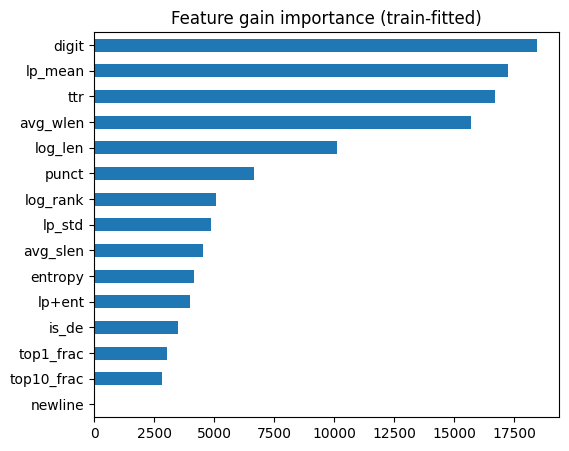

In [18]:
# (3) importance of perplexity/stylometry features in the model fitted on train
cols = ["lp_mean","lp_std","entropy","lp+ent","top1_frac","top10_frac","log_rank","avg_wlen","avg_slen","ttr","punct","newline","digit","log_len","is_de"]
pd.Series(gbm.booster_.feature_importance("gain"), index=cols).sort_values().plot.barh(figsize=(6,5)); plt.title("Feature gain importance (train-fitted)"); plt.show()

In [19]:
# (2) SHAP token attributions for the encoder, using the same head+tail preprocessing as training
import shap
def f_shap(texts): return predict_proba_ids(model, [ids_head_tail(str(t)) for t in texts], bs=16)
explainer = shap.Explainer(f_shap, shap.maskers.Text(tok), output_names=LABELS)
ex = va[va.n_words < 150].groupby("label").head(1).text.tolist()      # short texts keep SHAP cheap
sv = explainer(ex, max_evals=500)
for i in range(len(ex)): shap.plots.text(sv[i])

## 7. Candidate submission files
Writes one validated CSV per candidate model to `OUT_DIR`. **Nothing is submitted to Kaggle**; pick which file(s) to upload after reading the summary table. Note this runs inference on the 25,000 test texts (encoder, chunked encoder and Qwen perplexity features).

In [20]:
def make_submission(pred_idx, name):
    sub = pd.DataFrame({"id": test.id.values, "label": [LABELS[i] for i in pred_idx]}).set_index("id").loc[sub_tmpl.id].reset_index()
    assert set(sub_tmpl.label.unique()) <= set(LABELS), f"sample submission uses other label strings: {sub_tmpl.label.unique()}"
    assert list(sub.columns) == ["id","label"] and len(sub) == len(sub_tmpl) == 25000
    assert sub.id.is_unique and sub.id.tolist() == sub_tmpl.id.tolist() and sub.label.notna().all() and sub.label.isin(LABELS).all()
    sub.to_csv(f"{OUT_DIR}/{name}.csv", index=False); print("saved", name, sub.label.value_counts(normalize=True).round(3).to_dict()); return sub

# test probabilities of every candidate
P_enc_te = predict_proba_ids(model, DS(test.text.tolist()).ids)
P_ens_te = W*P_enc_te + (1-W)*P_base_te
P_chunk_te = predict_chunked(model, test.text.tolist())
model.to("cpu"); gc.collect(); torch.cuda.empty_cache(); lm.to(dev)        # Qwen needs the GPU for the 5b test features
F_te = np.hstack([ppl_features(test.text.tolist()), stylo(test.text)])
lm.to("cpu"); gc.collect(); torch.cuda.empty_cache(); model.to(dev)
P_feat_te = gbm.predict_proba(np.hstack([F_te, (test.lang=="de-DE").astype(float).values[:,None]]))
P_encfeat_te = WF*P_enc_te + (1-WF)*P_feat_te
np.savez(f"{OUT_DIR}/probs.npz", yva=yva, P_enc_va=P_enc_va, P_base_va=P_base_va, P_ens_va=P_ens_va, P_chunk_va=P_chunk_va, P_feat_va=P_feat_va, P_encfeat_va=P_encfeat_va,
         P_enc_te=P_enc_te, P_base_te=P_base_te, P_ens_te=P_ens_te, P_chunk_te=P_chunk_te, P_feat_te=P_feat_te, P_encfeat_te=P_encfeat_te)

files = {"sub_tfidf_logreg": (P_base_te, P_base_va), "sub_encoder": (P_enc_te, P_enc_va), "sub_chunked": (P_chunk_te, P_chunk_va),
         "sub_ensemble": (P_ens_te, P_ens_va), "sub_enc_ppl_blend": (P_encfeat_te, P_encfeat_va)}
for name, (Pte, Pva) in files.items():
    print(f"{name}: val macro-F1 {mf1(yva, Pva.argmax(1)):.4f}"); make_submission(Pte.argmax(1), name)
print(summary.round(4).to_string(index=False))
import subprocess, sys   # environment record for reproducibility
with open(f"{OUT_DIR}/requirements_installed.txt","w") as f: subprocess.run([sys.executable,"-m","pip","freeze"], stdout=f, check=True)
print(sys.version.split()[0], torch.__version__, torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "| N_SUB", N_SUB, "SEED", SEED)

sub_tfidf_logreg: val macro-F1 0.8644
saved sub_tfidf_logreg {'ai': 0.516, 'human': 0.28, 'fusion': 0.203}
sub_encoder: val macro-F1 0.8907
saved sub_encoder {'ai': 0.523, 'fusion': 0.246, 'human': 0.231}
sub_chunked: val macro-F1 0.8536
saved sub_chunked {'ai': 0.525, 'fusion': 0.281, 'human': 0.194}
sub_ensemble: val macro-F1 0.9026
saved sub_ensemble {'ai': 0.522, 'fusion': 0.244, 'human': 0.234}
sub_enc_ppl_blend: val macro-F1 0.8928
saved sub_enc_ppl_blend {'ai': 0.523, 'fusion': 0.245, 'human': 0.232}
                                               experiment  val_macroF1  delta_vs_encoder
TF-IDF baseline (LogReg, best family by internal holdout)       0.8644           -0.0262
                     TF-IDF LogReg (used in the ensemble)       0.8644           -0.0262
                   xlm-roberta-base head+tail (reference)       0.8907            0.0000
                              5a chunk-averaged inference       0.8536           -0.0370
                5b ppl+stylo features only

### Run instructions
1. Set `DATA_DIR`, run all cells top to bottom (GPU needed from section 4). Outputs go to `./outputs`: candidate CSVs (`sub_baseline.csv`, `sub_tfidf_logreg.csv`, `sub_encoder.csv`, `sub_chunked.csv`, `sub_ensemble.csv`, `sub_enc_ppl_blend.csv`), `summary.csv`, `leakage_robustness.csv`, `probs.npz`, saved encoder + tokenizer + train_config.json.
2. Seeds are fixed (`SEED=42`), the subsample and split are fixed, so the validation numbers are comparable across experiments.
3. Report checklist: EDA findings, baseline vs encoder on the same split, at least two experiments from section 5 (including those that failed), the final model (choose among the candidate CSVs after reading the summary table) and which two submissions you selected on Kaggle. Mention in the report: validation is probably optimistic because of sibling leakage (see `nn_sim` and `leakage_robustness.csv`), so expect the Kaggle score to be lower; the 0.5 ensemble weights favour the more confident encoder. Write the report yourself (AI tools are not allowed for it) and keep it to 1–2 pages.